# Systèmes Radar — Bureau d'études pratique (suite)
## Notebook interactif — Formation initiation radar
*Ateliers 3, 4 et 5 — Équation radar & Radar météo*

---

> **Rappel** : Ce notebook fait suite à la partie 1 (Ateliers 1 & 2). Les imports (`numpy`, `matplotlib`, constante `c`) sont supposés déjà chargés. Relancez la cellule d'initialisation si nécessaire.

*Dernière mise a jour: 16 juin 2026*

In [1]:
# ── Cellule d'initialisation (à relancer si nécessaire) ─────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import AutoMinorLocator

c = 3e8   # vitesse de la lumière (m/s)
print("Bibliothèques chargées.")
print(f"   c = {c:.2e} m/s")

Bibliothèques chargées.
   c = 3.00e+08 m/s


# Partie 2 — L'équation radar

## 2.1 Présentation

L'**équation radar** relie la puissance du signal reçu à l'ensemble des paramètres du système (émetteur, antennes, cible, distance). Elle est fondamentale pour :

- la **conception** de systèmes radar,
- l'**analyse des performances**,
- les **contre-mesures électroniques (ECM)**.

## 2.2 Formulation

$$P_r = \frac{P_e \cdot G_e \cdot G_r \cdot \lambda^2 \cdot \sigma}{(4\pi)^3 \cdot R^4}$$

avec :

| Symbole | Grandeur | Unité |
|---|---|---|
| $P_r$ | Puissance reçue | W |
| $P_e$ | Puissance émise (crête) | W |
| $G_e$ | Gain de l'antenne d'émission | (linéaire) |
| $G_r$ | Gain de l'antenne de réception | (linéaire) |
| $\lambda = c/f$ | Longueur d'onde | m |
| $\sigma$ | Surface Équivalente Radar (SER) | m² |
| $R$ | Distance radar-cible | m |

## 2.3 Formulation en décibels

En pratique, on utilise la **forme logarithmique** qui transforme les produits en sommes :

$$P_r\ (\text{dBm}) = P_e\ (\text{dBm}) + G_e\ (\text{dBi}) + G_r\ (\text{dBi}) + \sigma\ (\text{dBm}^2) + 20\log(\lambda) - 40\log(R) - 33$$

> La constante $-33$ provient du développement de $(4\pi)^3$ en dB.

## 2.4 Rappels sur les unités logarithmiques

$$\text{dBm} : P(\text{dBm}) = 10\log_{10}\left(\frac{P(\text{W})}{10^{-3}}\right)$$

$$\text{dBi} : G(\text{dBi}) = 10\log_{10}(G_{\text{linéaire}})$$

$$\text{dBm}^2 : \sigma(\text{dBm}^2) = 10\log_{10}(\sigma(\text{m}^2))$$

## 2.5 Portée maximale

En isolant $R$ dans l'équation radar, on obtient la **portée maximale** $R_{\max}$ pour une puissance minimale détectable $P_{r,\min}$ :

$$R_{\max} = \left(\frac{P_e \cdot G_e \cdot G_r \cdot \lambda^2 \cdot \sigma}{(4\pi)^3 \cdot P_{r,\min}}\right)^{1/4}$$

En dB, on isole $40\log(R_{\max})$ :

$$40\log(R_{\max}) = P_e + G_e + G_r + \sigma + 20\log(\lambda) - P_{r,\min} - 33$$

In [2]:
# ── Cellule : fonctions utilitaires dB ──────────────────────────────────────

def W_to_dBm(P_W):
    """Convertit une puissance en Watts vers dBm."""
    return 10 * np.log10(P_W / 1e-3)

def dBm_to_W(P_dBm):
    """Convertit une puissance en dBm vers Watts."""
    return 1e-3 * 10 ** (P_dBm / 10)

def lin_to_dBi(G_lin):
    """Convertit un gain linéaire en dBi."""
    return 10 * np.log10(G_lin)

def dBi_to_lin(G_dBi):
    """Convertit un gain en dBi vers linéaire."""
    return 10 ** (G_dBi / 10)

def sigma_to_dBsm(sigma_m2):
    """Convertit une SER en m² vers dBm²."""
    return 10 * np.log10(sigma_m2)

def freq_to_lambda(f_Hz):
    """Calcule la longueur d'onde depuis la fréquence."""
    return c / f_Hz

def puissance_recue_dBm(Pe_dBm, Ge_dBi, Gr_dBi, sigma_dBsm, f_Hz, R_m):
    """
    Calcule la puissance reçue (dBm) via l'équation radar logarithmique.
    Pr(dBm) = Pe + Ge + Gr + sigma + 20*log(lambda) - 40*log(R) - 33
    """
    lam = freq_to_lambda(f_Hz)
    return (Pe_dBm + Ge_dBi + Gr_dBi + sigma_dBsm
            + 20 * np.log10(lam) - 40 * np.log10(R_m) - 33)

def portee_max_m(Pe_dBm, Ge_dBi, Gr_dBi, sigma_dBsm, f_Hz, Prmin_dBm):
    """
    Calcule la portée maximale (m) depuis l'équation radar (forme dB).
    40*log(Rmax) = Pe + Ge + Gr + sigma + 20*log(lambda) - Prmin - 33
    """
    lam = freq_to_lambda(f_Hz)
    log_R = (Pe_dBm + Ge_dBi + Gr_dBi + sigma_dBsm
             + 20 * np.log10(lam) - Prmin_dBm - 33) / 40
    return 10 ** log_R

# Test rapide
print("Fonctions utilitaires chargées. Tests :")
print(f"  10 kW  → {W_to_dBm(10e3):.1f} dBm")
print(f"  G=2000 → {lin_to_dBi(2000):.1f} dBi")
print(f"  σ=2 m² → {sigma_to_dBsm(2):.2f} dBm²")
print(f"  f=3GHz → λ = {freq_to_lambda(3e9)*100:.2f} cm")

Fonctions utilitaires chargées. Tests :
  10 kW  → 70.0 dBm
  G=2000 → 33.0 dBi
  σ=2 m² → 3.01 dBm²
  f=3GHz → λ = 10.00 cm


# Atelier 3 — Utilisation de l'équation radar (radar TRACS)

## Énoncé

On cherche à déterminer la **puissance d'émission** d'un radar de contrôle de trafic aérien (TRACS) ayant les caractéristiques suivantes :

| Paramètre | Valeur |
|---|---|
| Puissance minimale détectable | $P_{r,\min} = 10^{-13}$ W |
| Gain antenne (émission = réception) | $G = 2000$ |
| Fréquence | $F = 1.3$ GHz |
| PRF | $PRF = 520$ Hz |
| SER de cible | $\sigma = 2.0$ m² |

**Questions :**

1. Calculer la longueur d'onde $\lambda$.
2. Exprimer toutes les grandeurs en dB, dBi, dBm.
3. Déterminer la portée maximale du radar $R_{\max}$.
4. Déterminer la puissance d'émission $P_e$ en dBm.
5. En déduire $P_e$ en Watts.

---

## Démarche

### Étape 1 — Longueur d'onde

$$\lambda = \frac{c}{f}$$

### Étape 2 — Conversions

$$P_{r,\min}(\text{dBm}) = 10\log_{10}\left(\frac{P_{r,\min}(\text{W})}{10^{-3}}\right)$$

$$G(\text{dBi}) = 10\log_{10}(G_{\text{lin}})$$

$$\sigma(\text{dBm}^2) = 10\log_{10}(\sigma(\text{m}^2))$$

### Étape 3 — Portée maximale

La portée est donnée par la fréquence de répétition (distance d'ambiguïté) :

$$R_{\max} = \frac{c \cdot PRT}{2} = \frac{c}{2 \cdot PRF}$$

> *Remarque : ici $R_{\max}$ est fournie par la PRF (portée non ambiguë), pas par la puissance.*

### Étape 4 — Puissance d'émission

On isole $P_e$ dans l'équation radar logarithmique :

$$P_e(\text{dBm}) = P_{r,\min} - G_e - G_r - \sigma + 40\log(R_{\max}) - 20\log(\lambda) + 33$$

In [3]:
# ── Cellule : CORRECTION Atelier 3 ──────────────────────────────────────────

print("=" * 60)
print("   CORRECTION — Atelier 3 : Radar TRACS")
print("=" * 60)

# Données
Prmin_A3  = 1e-13        # W
G_lin_A3  = 2000         # gain linéaire (émission = réception)
f_A3      = 1.3e9        # Hz
PRF_A3    = 520          # Hz
sigma_A3  = 2.0          # m²

# ── Étape 1 : longueur d'onde ────────────────────────────────
lam_A3 = freq_to_lambda(f_A3)
print(f"\n① Longueur d'onde")
print(f"   λ = c/f = {c:.2e} / {f_A3:.2e} = {lam_A3:.4f} m  ({lam_A3*100:.2f} cm)")

# ── Étape 2 : conversions dB ─────────────────────────────────
Prmin_dBm_A3  = W_to_dBm(Prmin_A3)
Ge_dBi_A3     = lin_to_dBi(G_lin_A3)
Gr_dBi_A3     = Ge_dBi_A3            # même antenne
sigma_dBsm_A3 = sigma_to_dBsm(sigma_A3)

print(f"\n② Conversions")
print(f"   Prmin = {Prmin_A3:.0e} W  →  {Prmin_dBm_A3:.1f} dBm")
print(f"   G     = {G_lin_A3}      →  {Ge_dBi_A3:.1f} dBi")
print(f"   σ     = {sigma_A3} m²    →  {sigma_dBsm_A3:.2f} dBm²")
print(f"   λ     = {lam_A3:.4f} m   →  20·log(λ) = {20*np.log10(lam_A3):.2f} dB")

# ── Étape 3 : portée maximale (non ambiguë) ──────────────────
PRT_A3   = 1 / PRF_A3
R_max_A3 = c * PRT_A3 / 2

print(f"\n③ Portée maximale (distance non ambiguë)")
print(f"   PRT   = 1/PRF = 1/{PRF_A3} = {PRT_A3*1e3:.3f} ms")
print(f"   Rmax  = c·PRT/2 = {R_max_A3/1e3:.1f} km")

# ── Étape 4 : puissance d'émission en dBm ────────────────────
# On isole Pe : Pe = Prmin - Ge - Gr - sigma + 40*log(R) - 20*log(lam) + 33
Pe_dBm_A3 = (Prmin_dBm_A3
             - Ge_dBi_A3
             - Gr_dBi_A3
             - sigma_dBsm_A3
             + 40 * np.log10(R_max_A3)
             - 20 * np.log10(lam_A3)
             + 33)

print(f"\n④ Puissance d'émission (dBm)")
print(f"   Pe = Prmin - Ge - Gr - σ + 40·log(Rmax) - 20·log(λ) + 33")
print(f"   Pe = {Prmin_dBm_A3:.1f} - {Ge_dBi_A3:.1f} - {Gr_dBi_A3:.1f} "
      f"- {sigma_dBsm_A3:.2f} + {40*np.log10(R_max_A3):.1f} "
      f"- ({20*np.log10(lam_A3):.1f}) + 33")
print(f"   Pe = {Pe_dBm_A3:.1f} dBm")

# ── Étape 5 : puissance en Watts ─────────────────────────────
Pe_W_A3 = dBm_to_W(Pe_dBm_A3)
print(f"\n⑤ Puissance d'émission (Watts)")
print(f"   Pe = {Pe_W_A3/1e6:.2f} MW")

   CORRECTION — Atelier 3 : Radar TRACS

① Longueur d'onde
   λ = c/f = 3.00e+08 / 1.30e+09 = 0.2308 m  (23.08 cm)

② Conversions
   Prmin = 1e-13 W  →  -100.0 dBm
   G     = 2000      →  33.0 dBi
   σ     = 2.0 m²    →  3.01 dBm²
   λ     = 0.2308 m   →  20·log(λ) = -12.74 dB

③ Portée maximale (distance non ambiguë)
   PRT   = 1/PRF = 1/520 = 1.923 ms
   Rmax  = c·PRT/2 = 288.5 km

④ Puissance d'émission (dBm)
   Pe = Prmin - Ge - Gr - σ + 40·log(Rmax) - 20·log(λ) + 33
   Pe = -100.0 - 33.0 - 33.0 - 3.01 + 218.4 - (-12.7) + 33
   Pe = 95.1 dBm

⑤ Puissance d'émission (Watts)
   Pe = 3.24 MW


In [4]:
# ── Cellule : bilan en tableau (style cours) ─────────────────────────────────
print("\n  Bilan — Tableau de calcul (méthode dB)")
print("  " + "─" * 48)
print(f"  {'Grandeur':<35} {'+':<6} {'-':<6}")
print("  " + "─" * 48)

lignes = [
    (f"Pe = {Pe_W_A3/1e6:.2f} MW → {Pe_dBm_A3:.1f} dBm",        f"{Pe_dBm_A3:.1f}",  ""),
    (f"Ge = {G_lin_A3} → {Ge_dBi_A3:.1f} dBi",                   f"{Ge_dBi_A3:.1f}",  ""),
    (f"Gr = {G_lin_A3} → {Gr_dBi_A3:.1f} dBi",                   f"{Gr_dBi_A3:.1f}",  ""),
    (f"σ  = {sigma_A3} m² → {sigma_dBsm_A3:.2f} dBm²",           f"{sigma_dBsm_A3:.2f}", ""),
    (f"λ  = {lam_A3:.4f} m → 20·log(λ) = {20*np.log10(lam_A3):.1f} dB",
                                                                    "", f"{abs(20*np.log10(lam_A3)):.1f}"),
    (f"R  = {R_max_A3/1e3:.0f} km → 40·log(R) = {40*np.log10(R_max_A3):.1f} dB",
                                                                    "", f"{40*np.log10(R_max_A3):.1f}"),
    ("Constante (4π)³ → 33 dB",                                    "", "33"),
]

somme_plus  = Pe_dBm_A3 + Ge_dBi_A3 + Gr_dBi_A3 + sigma_dBsm_A3
somme_moins = abs(20*np.log10(lam_A3)) + 40*np.log10(R_max_A3) + 33

for nom, plus, moins in lignes:
    print(f"  {nom:<35} {plus:<6} {moins:<6}")

print("  " + "─" * 48)
print(f"  {'BILAN':<35} {somme_plus:<6.1f} {somme_moins:<6.1f}")
print(f"  {'Pr (dBm) = bilan + - bilan -':<35} {somme_plus - somme_moins:.1f} dBm")
print(f"\n  Vérification : Pr calculé = {Prmin_dBm_A3:.1f} dBm ")


  Bilan — Tableau de calcul (méthode dB)
  ────────────────────────────────────────────────
  Grandeur                            +      -     
  ────────────────────────────────────────────────
  Pe = 3.24 MW → 95.1 dBm             95.1         
  Ge = 2000 → 33.0 dBi                33.0         
  Gr = 2000 → 33.0 dBi                33.0         
  σ  = 2.0 m² → 3.01 dBm²             3.01         
  λ  = 0.2308 m → 20·log(λ) = -12.7 dB        12.7  
  R  = 288 km → 40·log(R) = 218.4 dB         218.4 
  Constante (4π)³ → 33 dB                    33    
  ────────────────────────────────────────────────
  BILAN                               164.1  264.1 
  Pr (dBm) = bilan + - bilan -        -100.0 dBm

  Vérification : Pr calculé = -100.0 dBm 


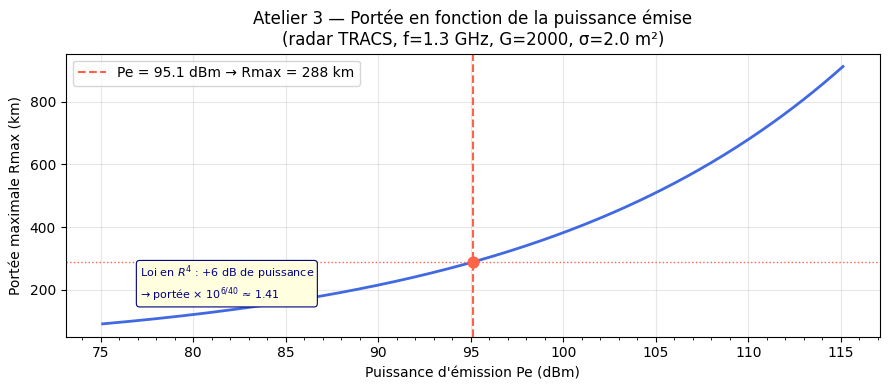

Illustration de la loi en R⁴ :
  Pe + -12 dB  →  Rmax =   144.6 km  (×0.50)
  Pe +  -6 dB  →  Rmax =   204.2 km  (×0.71)
  Pe +  -3 dB  →  Rmax =   242.7 km  (×0.84)
  Pe +  +0 dB  →  Rmax =   288.5 km  (×1.00)
  Pe +  +3 dB  →  Rmax =   342.8 km  (×1.19)
  Pe +  +6 dB  →  Rmax =   407.5 km  (×1.41)
  Pe + +10 dB  →  Rmax =   513.0 km  (×1.78)
  Pe + +12 dB  →  Rmax =   575.6 km  (×2.00)
  Pe + +20 dB  →  Rmax =   912.2 km  (×3.16)


In [7]:
# ── Cellule : sensibilité de la portée à la puissance émise ─────────────────
Pe_range_dBm = np.linspace(Pe_dBm_A3 - 20, Pe_dBm_A3 + 20, 300)
R_range_km   = np.array([portee_max_m(p, Ge_dBi_A3, Gr_dBi_A3,
                                       sigma_dBsm_A3, f_A3,
                                       Prmin_dBm_A3) / 1e3
                          for p in Pe_range_dBm])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(Pe_range_dBm, R_range_km, color='royalblue', lw=2)
ax.axvline(Pe_dBm_A3, color='tomato', lw=1.5, ls='--',
           label=f'Pe = {Pe_dBm_A3:.1f} dBm → Rmax = {R_max_A3/1e3:.0f} km')
ax.axhline(R_max_A3/1e3, color='tomato', lw=1, ls=':')
ax.scatter([Pe_dBm_A3], [R_max_A3/1e3], color='tomato', s=60, zorder=5)

ax.set_xlabel("Puissance d'émission Pe (dBm)")
ax.set_ylabel("Portée maximale Rmax (km)")
ax.set_title("Atelier 3 — Portée en fonction de la puissance émise\n"
             f"(radar TRACS, f={f_A3/1e9:.1f} GHz, G={G_lin_A3}, σ={sigma_A3} m²)")
ax.legend()
ax.grid(True, alpha=0.3)
ax.xaxis.set_minor_locator(AutoMinorLocator())

# Annotation : loi en R⁴
ax.text(Pe_dBm_A3 - 18, R_max_A3/1e3 * 0.6,
        "Loi en $R^4$ : +6 dB de puissance\n→ portée × $10^{6/40}$ ≈ 1.41",
        fontsize=8, color='navy',
        bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='navy', lw=0.8))

plt.tight_layout()
#plt.savefig("atelier3_portee.png", dpi=120)
plt.show()

# Illustration de la loi R^4
print("Illustration de la loi en R⁴ :")
for delta_Pe in [-12,-6, -3, 0, 3, 6, 10, 12, 20]:
    R = portee_max_m(Pe_dBm_A3 + delta_Pe, Ge_dBi_A3, Gr_dBi_A3,
                     sigma_dBsm_A3, f_A3, Prmin_dBm_A3) / 1e3
    print(f"  Pe + {delta_Pe:+3d} dB  →  Rmax = {R:7.1f} km  "
          f"(×{R/(R_max_A3/1e3):.2f})")

# Atelier 4 — Calcul de la puissance reçue

## Énoncé

Déterminer la **puissance reçue** par le système radar décrit ci-dessous :

| Paramètre | Valeur |
|---|---|
| Fréquence | $F = 2800$ MHz |
| Bande de fréquence | $B = 1.67$ MHz |
| PRF | $PRF = 1200$ Hz |
| Largeur d'impulsion | $\tau = 0.6\ \mu s$ |
| Puissance d'émission (crête) | $P_e = 1.4$ MW |
| Gain antenne | $G = 33$ dBi |
| Distance cible | $R = 110$ km |
| SER cible | $\sigma = 1$ m² |

**Question :** Calculer $P_r$ en dBm puis en Watts.

---

## Démarche

On applique directement la formule logarithmique :

$$P_r\ (\text{dBm}) = P_e\ (\text{dBm}) + G_e\ (\text{dBi}) + G_r\ (\text{dBi}) + \sigma\ (\text{dBm}^2) + 20\log(\lambda) - 40\log(R) - 33$$

Avec $\lambda = c/f$ et $R$ en mètres.

In [12]:
# ── Cellule : CORRECTION Atelier 4 ──────────────────────────────────────────

print("=" * 60)
print("   CORRECTION — Atelier 4 : Puissance reçue")
print("=" * 60)

# Données
f_A4      = 2800e6       # Hz
B_A4      = 1.67e6       # Hz  (bande passante — pour info)
PRF_A4    = 1200         # Hz
tau_A4    = 0.6e-6       # s
Pe_A4     = 1.4e6        # W  (puissance crête)
Ge_dBi_A4 = 33           # dBi  (émission = réception)
Gr_dBi_A4 = 33           # dBi
R_A4      = 110e3        # m
sigma_A4  = 1.0          # m²

# Calculs intermédiaires
lam_A4        = freq_to_lambda(f_A4)
Pe_dBm_A4     = W_to_dBm(Pe_A4)
sigma_dBsm_A4 = sigma_to_dBsm(sigma_A4)

print(f"\n  Données converties :")
print(f"  f     = {f_A4/1e6:.0f} MHz  →  λ = {lam_A4*100:.3f} cm")
print(f"  Pe    = {Pe_A4/1e6:.1f} MW   →  {Pe_dBm_A4:.1f} dBm")
print(f"  Ge    = {Ge_dBi_A4} dBi")
print(f"  Gr    = {Gr_dBi_A4} dBi")
print(f"  σ     = {sigma_A4} m²   →  {sigma_dBsm_A4:.0f} dBm²")
print(f"  R     = {R_A4/1e3:.0f} km")

# Calcul terme par terme
terme_Pe     = Pe_dBm_A4
terme_Ge     = Ge_dBi_A4
terme_Gr     = Gr_dBi_A4
terme_sigma  = sigma_dBsm_A4
terme_lam    = 20 * np.log10(lam_A4)
terme_R      = 40 * np.log10(R_A4)
terme_cst    = 33

somme_plus  = terme_Pe + terme_Ge + terme_Gr + terme_sigma
somme_moins = -terme_lam + terme_R + terme_cst   # lambda est négatif

Pr_dBm_A4 = puissance_recue_dBm(Pe_dBm_A4, Ge_dBi_A4, Gr_dBi_A4,
                                  sigma_dBsm_A4, f_A4, R_A4)
Pr_W_A4   = dBm_to_W(Pr_dBm_A4)

# Tableau de bilan
print(f"\n  Tableau de calcul (méthode dB)")
print("  " + "─" * 52)
print(f"  {'Grandeur':<38} {'+':<7} {'-':<7}")
print("  " + "─" * 52)

lignes_A4 = [
    (f"Pe = {Pe_A4/1e6:.1f} MW → {Pe_dBm_A4:.1f} dBm",      f"{terme_Pe:.1f}",   ""),
    (f"Ge = {Ge_dBi_A4} dBi",                                  f"{terme_Ge}",       ""),
    (f"Gr = {Gr_dBi_A4} dBi",                                  f"{terme_Gr}",       ""),
    (f"σ  = {sigma_A4} m² → {sigma_dBsm_A4:.0f} dBm²",        f"{terme_sigma:.0f}",""),
    (f"λ  = {lam_A4*100:.3f} cm → 20·log(λ) = {terme_lam:.1f} dB",
                                                                 "",                 f"{abs(terme_lam):.1f}"),
    (f"R  = {R_A4/1e3:.0f} km → 40·log(R) = {terme_R:.0f} dB","",                 f"{terme_R:.0f}"),
    ("Constante (4π)³ → 33 dB",                                 "",                  "33"),
]

sp, sm = 0.0, 0.0
for nom, plus, moins in lignes_A4:
    print(f"  {nom:<38} {plus:<7} {moins:<7}")
    if plus:  sp += float(plus)
    if moins: sm += float(moins)

print("  " + "─" * 52)
print(f"  {'BILAN':<38} {sp:<7.1f} {sm:<7.1f}")
print(f"  {'Pr (dBm) = Bilan+ − Bilan−':<38} {sp - sm:.1f} dBm")
print(f"\n Puissance reçue : Pr = {Pr_dBm_A4:.1f} dBm")
print(f"                   Pr = {Pr_W_A4*1e12:.2f} pW  ({Pr_W_A4:.2e} W)")

   CORRECTION — Atelier 4 : Puissance reçue

  Données converties :
  f     = 2800 MHz  →  λ = 10.714 cm
  Pe    = 1.4 MW   →  91.5 dBm
  Ge    = 33 dBi
  Gr    = 33 dBi
  σ     = 1.0 m²   →  0 dBm²
  R     = 110 km

  Tableau de calcul (méthode dB)
  ────────────────────────────────────────────────────
  Grandeur                               +       -      
  ────────────────────────────────────────────────────
  Pe = 1.4 MW → 91.5 dBm                 91.5           
  Ge = 33 dBi                            33             
  Gr = 33 dBi                            33             
  σ  = 1.0 m² → 0 dBm²                   0              
  λ  = 10.714 cm → 20·log(λ) = -19.4 dB          19.4   
  R  = 110 km → 40·log(R) = 202 dB               202    
  Constante (4π)³ → 33 dB                        33     
  ────────────────────────────────────────────────────
  BILAN                                  157.5   254.4  
  Pr (dBm) = Bilan+ − Bilan−             -96.9 dBm

 Puissance reçue : P

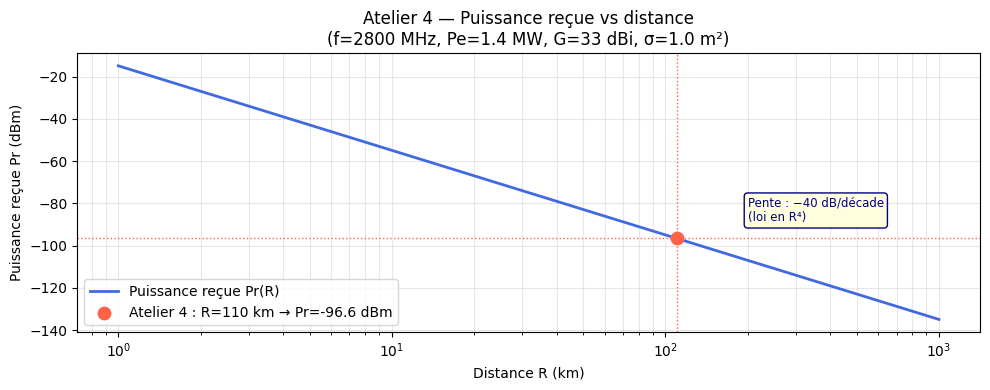

In [13]:
# ── Cellule : évolution de Pr en fonction de la distance ─────────────────────
R_range = np.logspace(3, 6, 500)   # de 1 km à 1000 km

Pr_range = puissance_recue_dBm(Pe_dBm_A4, Ge_dBi_A4, Gr_dBi_A4,
                                sigma_dBsm_A4, f_A4, R_range)

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogx(R_range / 1e3, Pr_range, color='royalblue', lw=2,
            label='Puissance reçue Pr(R)')

# Point de l'atelier
ax.scatter([R_A4/1e3], [Pr_dBm_A4], color='tomato', zorder=5, s=80,
           label=f'Atelier 4 : R={R_A4/1e3:.0f} km → Pr={Pr_dBm_A4:.1f} dBm')
ax.axhline(Pr_dBm_A4, color='tomato', lw=1, ls=':')
ax.axvline(R_A4/1e3,  color='tomato', lw=1, ls=':')

# Pente théorique −40 dB/décade
ax.text(200, Pr_dBm_A4 + 8,
        "Pente : −40 dB/décade\n(loi en R⁴)",
        fontsize=8.5, color='navy',
        bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='navy'))

ax.set_xlabel("Distance R (km)")
ax.set_ylabel("Puissance reçue Pr (dBm)")
ax.set_title(f"Atelier 4 — Puissance reçue vs distance\n"
             f"(f={f_A4/1e6:.0f} MHz, Pe={Pe_A4/1e6:.1f} MW, G={Ge_dBi_A4} dBi, σ={sigma_A4} m²)")
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
#plt.savefig("atelier4_pr_vs_R.png", dpi=120)
plt.show()

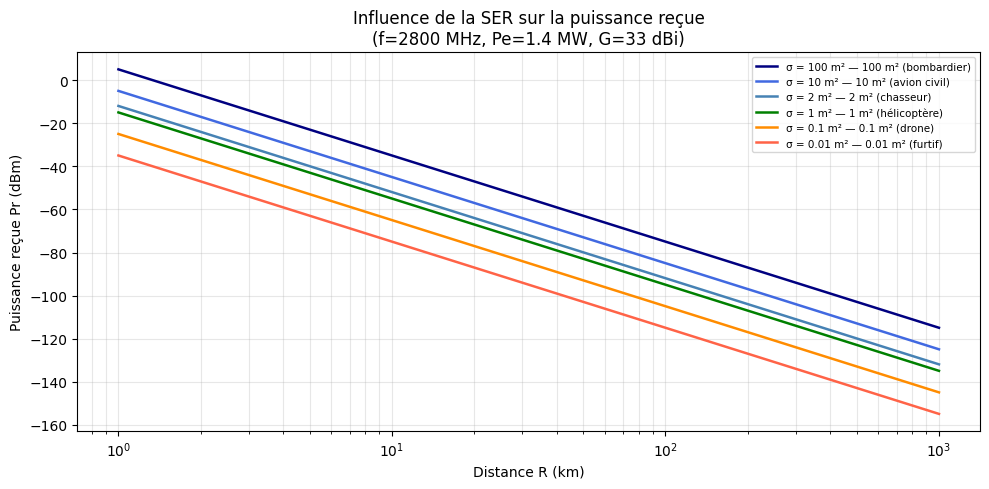

Impact de la furtivité (réduction de SER) à R = 110 km :
  σ = 100.00 m²  (100 m² (bombardier)      )  →  Pr = -76.6 dBm
  σ = 10.00 m²  (10 m² (avion civil)      )  →  Pr = -86.6 dBm
  σ =  2.00 m²  (2 m² (chasseur)          )  →  Pr = -93.6 dBm
  σ =  1.00 m²  (1 m² (hélicoptère)       )  →  Pr = -96.6 dBm
  σ =  0.10 m²  (0.1 m² (drone)           )  →  Pr = -106.6 dBm
  σ =  0.01 m²  (0.01 m² (furtif)         )  →  Pr = -116.6 dBm


In [14]:
# ── Cellule : influence de la SER (furtivité) ────────────────────────────────
# Question bonus : que se passe-t-il si la cible est furtive ?

sigmas_m2  = [100, 10, 2, 1, 0.1, 0.01]
sigmas_lbl = ['100 m² (bombardier)', '10 m² (avion civil)', '2 m² (chasseur)',
              '1 m² (hélicoptère)', '0.1 m² (drone)', '0.01 m² (furtif)']
couleurs   = ['navy', 'royalblue', 'steelblue', 'green', 'darkorange', 'tomato']

fig, ax = plt.subplots(figsize=(10, 5))

for sig, lbl, col in zip(sigmas_m2, sigmas_lbl, couleurs):
    Pr_sig = puissance_recue_dBm(Pe_dBm_A4, Ge_dBi_A4, Gr_dBi_A4,
                                  sigma_to_dBsm(sig), f_A4, R_range)
    ax.semilogx(R_range / 1e3, Pr_sig, color=col, lw=1.8, label=f'σ = {sig} m² — {lbl}')

ax.set_xlabel("Distance R (km)")
ax.set_ylabel("Puissance reçue Pr (dBm)")
ax.set_title("Influence de la SER sur la puissance reçue\n"
             f"(f={f_A4/1e6:.0f} MHz, Pe={Pe_A4/1e6:.1f} MW, G={Ge_dBi_A4} dBi)")
ax.legend(fontsize=7.5, loc='upper right')
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
#plt.savefig("atelier4_SER.png", dpi=120)
plt.show()

print("Impact de la furtivité (réduction de SER) à R = 110 km :")
for sig, lbl in zip(sigmas_m2, sigmas_lbl):
    Pr = puissance_recue_dBm(Pe_dBm_A4, Ge_dBi_A4, Gr_dBi_A4,
                              sigma_to_dBsm(sig), f_A4, R_A4)
    print(f"  σ = {sig:5.2f} m²  ({lbl:<25})  →  Pr = {Pr:.1f} dBm")

# Atelier 5 — Radar météo TWR-850/WXR-840 (Rockwell-Collins)

## Énoncé

On étudie un radar météorologique embarqué sur aéronef, le **TWR-850/WXR-840** de Rockwell-Collins, dont les spécifications constructeur sont les suivantes :

| Paramètre | Valeur |
|---|---|
| Référence | RTA-800 |
| Portée maximale | 340 nm |
| Portées disponibles | 5, 10, 25, 50, 100, 200, 300 nm |
| Puissance émise | 35 W nominal |
| Fréquence | Bande X |
| Largeurs d'impulsion | 1,8 / 2,4 / 4,8 / 9,6 / 19,2 / 28,8 µs |
| Vitesse de balayage | 27°/s |
| Type d'antenne | Flat plate |
| Taille antenne | 30,5 cm (12 in) |
| Ouverture de faisceau | 8° |
| Angle de balayage | 120° |
| Inclinaison (tilt) | ±15° |

> **Rappel :** 1 mille nautique (nm) = 1852 m

**Questions :**

1. Déterminer les **bandes de fréquences** balayées par le radar.
2. Calculer la **bande de longueurs d'onde** utilisée.
3. Déterminer les **distances min et max** de détection.
4. Déterminer les **temps de vol** associés.
5. Déterminer la **précision en distance** (résolution).
6. Déterminer la **précision angulaire**.
7. Déterminer la **taille minimum de la surface de confusion**.
8. Estimer la **PRF probable**.

---

## Démarche

### Question 1 — Bande X

La bande X est définie entre **8 GHz et 12 GHz** (normes IEEE). Une recherche sur ce système précis indique une fréquence d'utilisation de **9,435 GHz**.

### Question 2 — Longueurs d'onde

$$\lambda = \frac{c}{f} \Rightarrow \begin{cases} f = 8\ \text{GHz} & \lambda = 3{,}75\ \text{cm} \\ f = 12\ \text{GHz} & \lambda = 2{,}5\ \text{cm} \end{cases}$$

### Question 3 — Distances de détection

La portée **minimale** correspond à la **distance aveugle** (impulsion la plus courte) :

$$D_{\min} = \frac{c \cdot \tau_{\min}}{2}$$

La portée **maximale** est donnée directement par le constructeur : 340 nm.

### Question 4 — Temps de vol

$$\Delta t = \frac{2 D}{c}$$

### Question 5 — Précision en distance (résolution)

$$\delta_r = \frac{c \cdot \tau}{2}$$

La durée d'impulsion varie selon la portée sélectionnée : la résolution varie donc également.

### Question 6 — Précision angulaire

Elle est déterminée par **l'ouverture à mi-puissance (−3 dB)** de l'antenne : $\theta_{3\text{dB}} = 8°$.

Deux cibles sont résolues angulairement si leur séparation angulaire est supérieure à $\theta_{3\text{dB}}$.

### Question 7 — Surface de confusion

Le **volume de confusion** est le volume de l'espace dans lequel deux cibles ne peuvent pas être distinguées. Il est délimité par :
- en distance : $\delta_r$ (résolution distance)
- en angle : $\theta_{3\text{dB}}$ (résolution angulaire)

La **distance transversale** associée à la résolution angulaire à une portée $D$ est :

$$d_\theta = D \cdot \theta_{3\text{dB}}\ (\text{en rad})$$

La surface de confusion (en km²) est alors :

$$S_{\text{confusion}} = \delta_r \times d_\theta$$

### Question 8 — PRF

La portée maximale non ambiguë impose une contrainte sur la PRF :

$$R_{\max} < \frac{c}{2 \cdot PRF} \Rightarrow PRF < \frac{c}{2 \cdot R_{\max}}$$

In [15]:
# ── Cellule : CORRECTION Atelier 5 ──────────────────────────────────────────

print("=" * 65)
print("   CORRECTION — Atelier 5 : Radar météo TWR-850/WXR-840")
print("=" * 65)

nm_to_m = 1852   # 1 mille nautique = 1852 m

# Données constructeur
f_X_min   = 8e9           # Hz  (bande X min)
f_X_max   = 12e9          # Hz  (bande X max)
f_exact   = 9.435e9       # Hz  (fréquence réelle du système)
taus_us   = [1.8, 2.4, 4.8, 9.6, 19.2, 28.8]  # µs
taus_s    = [t * 1e-6 for t in taus_us]
R_max_nm  = 340           # milles nautiques
R_min_nm  = 5             # milles nautiques (portée minimale disponible)
theta_3dB = 8             # degrés
Pe_A5     = 35            # W

R_max_m   = R_max_nm * nm_to_m
R_min_m   = R_min_nm * nm_to_m

# ── Q1 : Bandes de fréquences ────────────────────────────────
print(f"\n① Bandes de fréquences (bande X)")
print(f"   Définition IEEE : {f_X_min/1e9:.0f} GHz — {f_X_max/1e9:.0f} GHz")
print(f"   Fréquence réelle du système : {f_exact/1e9:.3f} GHz")

# ── Q2 : Longueurs d'onde ────────────────────────────────────
lam_min_X = freq_to_lambda(f_X_max)   # la lambda min correspond à f max
lam_max_X = freq_to_lambda(f_X_min)
lam_exact = freq_to_lambda(f_exact)

print(f"\n② Longueurs d'onde")
print(f"   f = {f_X_min/1e9:.0f} GHz  →  λ = {lam_max_X*100:.2f} cm")
print(f"   f = {f_X_max/1e9:.0f} GHz  →  λ = {lam_min_X*100:.2f} cm")
print(f"   f = {f_exact/1e9:.3f} GHz (réelle) → λ = {lam_exact*100:.2f} cm")

# ── Q3 : Distances de détection ──────────────────────────────
D_blind_min = c * min(taus_s) / 2   # distance aveugle avec impulsion la plus courte
D_blind_max = c * max(taus_s) / 2   # distance aveugle avec impulsion la plus longue

print(f"\n③ Distances de détection")
print(f"   Portée min constructeur  : {R_min_nm} nm = {R_min_m/1e3:.2f} km")
print(f"   Portée max constructeur  : {R_max_nm} nm = {R_max_m/1e3:.1f} km")
print(f"   Distance aveugle (τ min) : {D_blind_min:.0f} m  (τ = {min(taus_us)} µs)")
print(f"   Distance aveugle (τ max) : {D_blind_max/1e3:.2f} km  (τ = {max(taus_us)} µs)")

# ── Q4 : Temps de vol ────────────────────────────────────────
t_min = 2 * R_min_m / c
t_max = 2 * R_max_m / c

print(f"\n④ Temps de vol")
print(f"   Pour Dmin = {R_min_nm} nm = {R_min_m/1e3:.2f} km : "
      f"Δt = 2D/c = {t_min*1e6:.1f} µs")
print(f"   Pour Dmax = {R_max_nm} nm = {R_max_m/1e3:.1f} km : "
      f"Δt = 2D/c = {t_max*1e6:.0f} µs  ({t_max*1e3:.1f} ms)")

# ── Q5 : Résolution en distance ──────────────────────────────
print(f"\n⑤ Résolution en distance  δr = c·τ/2  (150 m par µs)")
print(f"   {'τ (µs)':<12} {'δr (m)':<12}")
print(f"   {'─'*22}")
for tau_us, tau_s in zip(taus_us, taus_s):
    dr = c * tau_s / 2
    print(f"   {tau_us:<12.1f} {dr:<12.0f}")

# ── Q6 : Précision angulaire ─────────────────────────────────
print(f"\n⑥ Précision angulaire")
print(f"   Ouverture à −3 dB : θ_3dB = {theta_3dB}°")
print(f"   Deux cibles sont résolues si leur écart angulaire > {theta_3dB}°")

# ── Q7 : Surface de confusion ────────────────────────────────
theta_rad = np.deg2rad(theta_3dB)
D_ref     = R_min_m          # à la portée minimale (cas le plus défavorable)
d_theta   = D_ref * theta_rad
tau_ref   = taus_s[0]        # τ = 1,8 µs (résolution la plus fine)
dr_ref    = c * tau_ref / 2

S_confusion = dr_ref * d_theta / 1e6   # en km²

print(f"\n⑦ Surface de confusion (à D = {R_min_nm} nm = {R_min_m/1e3:.2f} km)")
print(f"   θ_3dB  = {theta_3dB}° = {theta_rad:.4f} rad")
print(f"   d_θ    = D·θ_3dB = {D_ref/1e3:.2f} km × {theta_rad:.4f} = {d_theta:.0f} m")
print(f"   δr     = {dr_ref:.0f} m  (τ = {taus_us[0]} µs)")
print(f"   S_conf = δr × d_θ = {dr_ref:.0f} m × {d_theta:.0f} m = {S_confusion:.4f} km²")

# ── Q8 : PRF ─────────────────────────────────────────────────
PRF_max = c / (2 * R_max_m)

print(f"\n⑧ PRF probable")
print(f"   Rmax = {R_max_nm} nm = {R_max_m/1e3:.2f} km")
print(f"   PRF < c / (2·Rmax) = {c:.2e} / (2 × {R_max_m:.0f}) = {PRF_max:.1f} Hz")
print(f"   → La PRF doit être inférieure à ~{PRF_max:.0f} Hz")

   CORRECTION — Atelier 5 : Radar météo TWR-850/WXR-840

① Bandes de fréquences (bande X)
   Définition IEEE : 8 GHz — 12 GHz
   Fréquence réelle du système : 9.435 GHz

② Longueurs d'onde
   f = 8 GHz  →  λ = 3.75 cm
   f = 12 GHz  →  λ = 2.50 cm
   f = 9.435 GHz (réelle) → λ = 3.18 cm

③ Distances de détection
   Portée min constructeur  : 5 nm = 9.26 km
   Portée max constructeur  : 340 nm = 629.7 km
   Distance aveugle (τ min) : 270 m  (τ = 1.8 µs)
   Distance aveugle (τ max) : 4.32 km  (τ = 28.8 µs)

④ Temps de vol
   Pour Dmin = 5 nm = 9.26 km : Δt = 2D/c = 61.7 µs
   Pour Dmax = 340 nm = 629.7 km : Δt = 2D/c = 4198 µs  (4.2 ms)

⑤ Résolution en distance  δr = c·τ/2  (150 m par µs)
   τ (µs)       δr (m)      
   ──────────────────────
   1.8          270         
   2.4          360         
   4.8          720         
   9.6          1440        
   19.2         2880        
   28.8         4320        

⑥ Précision angulaire
   Ouverture à −3 dB : θ_3dB = 8°
   Deux cibles so

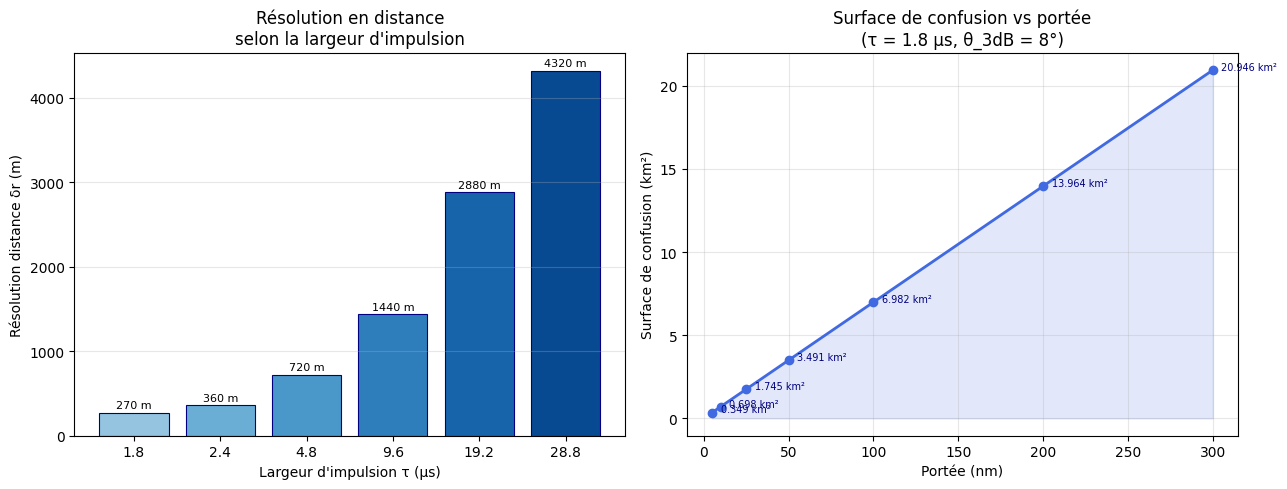

In [16]:
# ── Cellule : visualisation des résolutions en distance ──────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graphe gauche : résolution en distance par largeur d'impulsion
delta_rs = [c * t / 2 for t in taus_s]
colors_bar = plt.cm.Blues(np.linspace(0.4, 0.9, len(taus_us)))

bars = axes[0].bar([str(t) for t in taus_us], delta_rs,
                   color=colors_bar, edgecolor='navy', lw=0.8)
axes[0].set_xlabel("Largeur d'impulsion τ (µs)")
axes[0].set_ylabel("Résolution distance δr (m)")
axes[0].set_title("Résolution en distance\nselon la largeur d'impulsion")
axes[0].grid(axis='y', alpha=0.3)
for bar, dr in zip(bars, delta_rs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{dr:.0f} m', ha='center', va='bottom', fontsize=8)

# Graphe droit : surface de confusion à différentes portées
portees_nm  = [5, 10, 25, 50, 100, 200, 300]
portees_m   = [p * nm_to_m for p in portees_nm]
tau_plot    = taus_s[0]           # τ = 1.8 µs (meilleure résolution)
dr_plot     = c * tau_plot / 2    # 270 m

S_confs_km2 = []
for D in portees_m:
    d_th = D * theta_rad
    S_confs_km2.append(dr_plot * d_th / 1e6)

axes[1].plot(portees_nm, S_confs_km2, 'o-', color='royalblue', lw=2, ms=6)
axes[1].fill_between(portees_nm, S_confs_km2, alpha=0.15, color='royalblue')
axes[1].set_xlabel("Portée (nm)")
axes[1].set_ylabel("Surface de confusion (km²)")
axes[1].set_title(f"Surface de confusion vs portée\n"
                  f"(τ = {taus_us[0]} µs, θ_3dB = {theta_3dB}°)")
axes[1].grid(True, alpha=0.3)

for D_nm, S in zip(portees_nm, S_confs_km2):
    axes[1].annotate(f'{S:.3f} km²', xy=(D_nm, S),
                     xytext=(D_nm + 5, S + 0.01),
                     fontsize=7, color='navy')

plt.tight_layout()
#plt.savefig("atelier5_resolution.png", dpi=120)
plt.show()

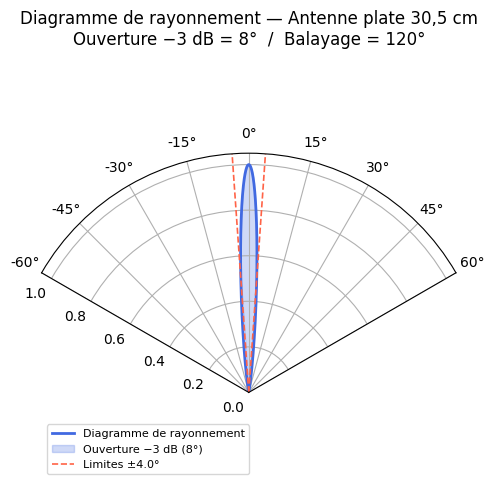

In [17]:
# ── Cellule : schéma polaire du faisceau radar ───────────────────────────────
fig = plt.figure(figsize=(9, 5))
ax  = fig.add_subplot(111, projection='polar')

theta_beam = np.deg2rad(np.linspace(-theta_3dB/2, theta_3dB/2, 300))
theta_full = np.deg2rad(np.linspace(-60, 60, 3000))   # balayage ±60° (120° total)

# Modèle de lobe simplifié (gaussien)
sigma_beam = np.deg2rad(theta_3dB / (2 * np.sqrt(2 * np.log(2))))
gain_pattern = np.exp(-theta_full**2 / (2 * sigma_beam**2))

ax.plot(theta_full, gain_pattern, color='royalblue', lw=2, label='Diagramme de rayonnement')
ax.fill_between(theta_beam,
                np.exp(-theta_beam**2 / (2 * sigma_beam**2)),
                alpha=0.25, color='royalblue', label=f'Ouverture −3 dB ({theta_3dB}°)')
ax.axvline(np.deg2rad(-theta_3dB/2), color='tomato', lw=1.2, ls='--')
ax.axvline(np.deg2rad( theta_3dB/2), color='tomato', lw=1.2, ls='--',
           label=f'Limites ±{theta_3dB/2}°')

ax.set_thetamin(-60)
ax.set_thetamax(60)
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
ax.set_title(f"Diagramme de rayonnement — Antenne plate 30,5 cm\n"
             f"Ouverture −3 dB = {theta_3dB}°  /  Balayage = 120°",
             pad=15)
ax.legend(loc='lower left', fontsize=8)

plt.tight_layout()
#plt.savefig("atelier5_lobe.png", dpi=120)
plt.show()

In [18]:
# ── Cellule : bilan complet Atelier 5 ───────────────────────────────────────
print("=" * 65)
print("   BILAN — Atelier 5 : Radar météo TWR-850/WXR-840")
print("=" * 65)
print(f"""
  1. Bande de fréquences
     Bande X : {f_X_min/1e9:.0f} – {f_X_max/1e9:.0f} GHz
     Fréquence réelle : {f_exact/1e9:.3f} GHz

  2. Longueurs d'onde
     f = {f_X_min/1e9:.0f} GHz → λ = {lam_max_X*100:.2f} cm
     f = {f_X_max/1e9:.0f} GHz → λ = {lam_min_X*100:.2f} cm

  3. Distances de détection
     Min : {R_min_nm} nm = {R_min_m/1e3:.2f} km
     Max : {R_max_nm} nm = {R_max_m/1e3:.1f} km

  4. Temps de vol
     t_min = {t_min*1e6:.1f} µs  (D = {R_min_nm} nm)
     t_max = {t_max*1e6:.0f} µs  (D = {R_max_nm} nm)

  5. Résolution en distance
     τ_min = {taus_us[0]} µs → δr = {c*taus_s[0]/2:.0f} m
     τ_max = {taus_us[-1]} µs → δr = {c*taus_s[-1]/2:.0f} m

  6. Précision angulaire
     θ_3dB = {theta_3dB}°

  7. Surface de confusion (D = {R_min_nm} nm, τ = {taus_us[0]} µs)
     d_θ  = {d_theta:.0f} m
     δr   = {dr_ref:.0f} m
     S    = {S_confusion:.4f} km²

  8. PRF probable
     PRF < {PRF_max:.0f} Hz
""")

   BILAN — Atelier 5 : Radar météo TWR-850/WXR-840

  1. Bande de fréquences
     Bande X : 8 – 12 GHz
     Fréquence réelle : 9.435 GHz

  2. Longueurs d'onde
     f = 8 GHz → λ = 3.75 cm
     f = 12 GHz → λ = 2.50 cm

  3. Distances de détection
     Min : 5 nm = 9.26 km
     Max : 340 nm = 629.7 km

  4. Temps de vol
     t_min = 61.7 µs  (D = 5 nm)
     t_max = 4198 µs  (D = 340 nm)

  5. Résolution en distance
     τ_min = 1.8 µs → δr = 270 m
     τ_max = 28.8 µs → δr = 4320 m

  6. Précision angulaire
     θ_3dB = 8°

  7. Surface de confusion (D = 5 nm, τ = 1.8 µs)
     d_θ  = 1293 m
     δr   = 270 m
     S    = 0.3491 km²

  8. PRF probable
     PRF < 238 Hz



# Synthèse générale — Tableau de bord radar

In [19]:
# ── Cellule : tableau de bord interactif comparant les 3 radars ─────────────

radars = {
    "Radar de poursuite\n(Atelier 2)": {
        "f_GHz": 3.0, "tau_us": 1.0, "PRF": 400, "Pc_kW": 800,
        "couleur": "royalblue"
    },
    "Radar TRACS\n(Atelier 3)": {
        "f_GHz": 1.3, "tau_us": None, "PRF": 520, "Pc_kW": 3240,
        "couleur": "green"
    },
    "Radar A4\n(Atelier 4)": {
        "f_GHz": 2.8, "tau_us": 0.6, "PRF": 1200, "Pc_kW": 1400,
        "couleur": "darkorange"
    },
}

print(f"{'Radar':<28} {'f (GHz)':<10} {'τ (µs)':<10} "
      f"{'PRF (Hz)':<10} {'Pc (kW)':<10} {'Rmax (km)':<12} {'δr (m)':<10}")
print("─" * 100)

for nom, p in radars.items():
    PRT   = 1 / p["PRF"]
    tau_s = p["tau_us"] * 1e-6 if p["tau_us"] else None
    Rmax  = (c * (PRT - tau_s) / 2 / 1e3) if tau_s else c / (2 * p["PRF"]) / 1e3
    dr    = (c * tau_s / 2) if tau_s else "—"
    tau_str = f"{p['tau_us']}" if p["tau_us"] else "variable"
    dr_str  = f"{dr:.0f}" if isinstance(dr, float) else dr
    print(f"{nom.replace(chr(10), ' '):<28} {p['f_GHz']:<10.1f} {tau_str:<10} "
          f"{p['PRF']:<10} {p['Pc_kW']:<10} {Rmax:<12.1f} {dr_str:<10}")

print()
print("Radar météo (Atelier 5) : bande X (8–12 GHz), τ variable (1,8 à 28,8 µs),")
print(f"  PRF < {PRF_max:.0f} Hz, Pc = 35 W, Rmax = {R_max_nm} nm = {R_max_m/1e3:.1f} km")

Radar                        f (GHz)    τ (µs)     PRF (Hz)   Pc (kW)    Rmax (km)    δr (m)    
────────────────────────────────────────────────────────────────────────────────────────────────────
Radar de poursuite (Atelier 2) 3.0        1.0        400        800        374.9        150       
Radar TRACS (Atelier 3)      1.3        variable   520        3240       288.5        —         
Radar A4 (Atelier 4)         2.8        0.6        1200       1400       124.9        90        

Radar météo (Atelier 5) : bande X (8–12 GHz), τ variable (1,8 à 28,8 µs),
  PRF < 238 Hz, Pc = 35 W, Rmax = 340 nm = 629.7 km
